<a href="https://colab.research.google.com/github/Gopikabs116/ML-Projects/blob/Sleep-Health-Detection/Random_Forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("/content/sleep_health_dataset.csv")
df

,person_id,age,gender,occupation,bmi,country,sleep_duration_hrs,sleep_quality_score,rem_percentage,deep_sleep_percentage,...,heart_rate_resting_bpm,sleep_aid_used,shift_work,room_temperature_celsius,weekend_sleep_diff_hrs,season,day_type,cognitive_performance_score,sleep_disorder_risk,felt_rested
0,1,29,Female,Driver,25.7,Japan,6.19,6.6,22.5,19.3,...,63,0,0,20.1,1.84,Autumn,Weekday,73.4,Healthy,0
1,2,55,Female,Software Engineer,22.0,USA,8.32,6.9,26.9,14.9,...,52,1,0,18.0,0.13,Winter,Weekend,99.4,Healthy,1
2,3,42,Male,Nurse,25.0,India,3.74,1.0,20.2,16.2,...,72,0,1,17.9,1.67,Spring,Weekend,2.5,Severe,0
3,4,37,Female,Student,29.5,India,6.79,6.4,17.7,17.7,...,71,0,0,19.1,2.37,Summer,Weekend,67.8,Healthy,0
4,5,23,Male,Lawyer,23.6,Spain,5.02,3.2,23.3,18.3,...,71,0,0,19.7,1.26,Summer,Weekday,38.1,Mild,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,99996,44,Female,Nurse,25.9,USA,6.77,6.3,26.8,24.6,...,72,1,0,19.1,1.93,Spring,Weekend,89.4,Healthy,1
99996,99997,44,Female,Manager,30.2,India,4.90,4.1,21.6,22.3,...,80,1,0,18.6,1.44,Spring,Weekday,40.5,Mild,0
99997,99998,39,Male,Manager,29.2,Brazil,5.94,5.1,21.4,14.3,...,74,1,0,19.4,0.62,Spring,Weekday,64.8,Healthy,1
99998,99999,33,Female,Nurse,27.3,India,5.27,3.0,21.9,23.6,...,68,1,0,20.6,2.32,Winter,Weekend,40.8,Mild,0


In [3]:
df.shape #counts total number of rows and columns

(100000, 32)

In [4]:
df.head() #display the first 5 rows of your DataFrame

,person_id,age,gender,occupation,bmi,country,sleep_duration_hrs,sleep_quality_score,rem_percentage,deep_sleep_percentage,...,heart_rate_resting_bpm,sleep_aid_used,shift_work,room_temperature_celsius,weekend_sleep_diff_hrs,season,day_type,cognitive_performance_score,sleep_disorder_risk,felt_rested
0,1,29,Female,Driver,25.7,Japan,6.19,6.6,22.5,19.3,...,63,0,0,20.1,1.84,Autumn,Weekday,73.4,Healthy,0
1,2,55,Female,Software Engineer,22.0,USA,8.32,6.9,26.9,14.9,...,52,1,0,18.0,0.13,Winter,Weekend,99.4,Healthy,1
2,3,42,Male,Nurse,25.0,India,3.74,1.0,20.2,16.2,...,72,0,1,17.9,1.67,Spring,Weekend,2.5,Severe,0
3,4,37,Female,Student,29.5,India,6.79,6.4,17.7,17.7,...,71,0,0,19.1,2.37,Summer,Weekend,67.8,Healthy,0
4,5,23,Male,Lawyer,23.6,Spain,5.02,3.2,23.3,18.3,...,71,0,0,19.7,1.26,Summer,Weekday,38.1,Mild,0


In [5]:
df.info()
#concise summary of your DataFrame df.
#It prints information like the total number of entries, the number of columns, the data type of each column (e.g., integer, float, object),
#the count of non-null values per column, and memory usage.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 32 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   person_id                    100000 non-null  int64  
 1   age                          100000 non-null  int64  
 2   gender                       100000 non-null  object 
 3   occupation                   100000 non-null  object 
 4   bmi                          100000 non-null  float64
 5   country                      100000 non-null  object 
 6   sleep_duration_hrs           100000 non-null  float64
 7   sleep_quality_score          100000 non-null  float64
 8   rem_percentage               100000 non-null  float64
 9   deep_sleep_percentage        100000 non-null  float64
 10  sleep_latency_mins           100000 non-null  int64  
 11  wake_episodes_per_night      100000 non-null  int64  
 12  caffeine_mg_before_bed       100000 non-null  int64  
 13  

In [6]:
df.isnull().sum()
# count the number of missing (null) values in each column

,0
person_id,0
age,0
gender,0
occupation,0
bmi,0
country,0
sleep_duration_hrs,0
sleep_quality_score,0
rem_percentage,0
deep_sleep_percentage,0


In [7]:
df.describe()

,person_id,age,bmi,sleep_duration_hrs,sleep_quality_score,rem_percentage,deep_sleep_percentage,sleep_latency_mins,wake_episodes_per_night,caffeine_mg_before_bed,...,nap_duration_mins,stress_score,work_hours_that_day,heart_rate_resting_bpm,sleep_aid_used,shift_work,room_temperature_celsius,weekend_sleep_diff_hrs,cognitive_performance_score,felt_rested
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,50000.500000,34.706870,26.289673,6.423986,4.871144,20.243968,20.253375,19.836810,3.346610,38.849500,...,14.936840,5.733285,7.134059,66.57017,0.561610,0.084420,20.538093,1.200634,59.227295,0.390120
std,28867.657797,11.036373,4.479578,1.274627,1.506517,3.411354,4.251096,7.584343,1.920877,69.395818,...,21.387567,1.619194,3.482878,7.22821,0.496192,0.278018,2.897565,0.786667,22.249665,0.487779
min,1.000000,18.000000,16.000000,3.000000,1.000000,10.000000,5.000000,1.000000,0.000000,0.000000,...,0.000000,1.000000,0.000000,45.00000,0.000000,0.000000,15.000000,-1.000000,0.000000,0.000000
25%,25000.750000,26.000000,23.200000,5.530000,3.800000,18.000000,17.400000,14.000000,2.000000,0.000000,...,0.000000,4.800000,4.700000,62.00000,0.000000,0.000000,18.500000,0.670000,44.200000,0.000000
50%,50000.500000,33.000000,26.300000,6.360000,4.900000,20.300000,20.300000,19.000000,3.000000,0.000000,...,0.000000,5.800000,7.400000,67.00000,1.000000,0.000000,20.500000,1.200000,60.400000,0.000000
75%,75000.250000,42.000000,29.300000,7.270000,6.000000,22.600000,23.200000,25.000000,5.000000,80.000000,...,30.000000,6.800000,9.700000,71.00000,1.000000,0.000000,22.500000,1.740000,75.800000,1.000000
max,100000.000000,69.000000,45.000000,10.500000,10.000000,30.000000,30.000000,58.000000,8.000000,400.000000,...,116.000000,10.000000,18.000000,99.00000,1.000000,1.000000,28.000000,3.000000,100.000000,1.000000


In [8]:
df_clean=df.drop(columns=['person_id'])
#creates a new DataFrame called df_clean
#by removing the 'person_id' column from the original df DataFrame.

In [9]:
y = df_clean['sleep_disorder_risk']
#extracting a specific column, 'sleep_disorder_risk',
#from the df_clean DataFrame and assigning it to a new variable y.
#In the context of machine learning, y typically represents the target variable
#(or dependent variable) that you want to predict or analyze.

In [10]:
x = df_clean.drop(columns=['sleep_disorder_risk'])
#creates a new DataFrame called x by removing the 'sleep_disorder_risk' column
#from the df_clean DataFrame. In the context of machine learning, x typically
#represents your feature matrix (or independent variables) that you will use to
#predict the target variable y

In [11]:
print("Features shape (x):", x.shape)
print("Target shape (y):", y.shape)

Features shape (x): (100000, 30)
Target shape (y): (100000,)


In [12]:
x.dtypes

,0
age,int64
gender,object
occupation,object
bmi,float64
country,object
sleep_duration_hrs,float64
sleep_quality_score,float64
rem_percentage,float64
deep_sleep_percentage,float64
sleep_latency_mins,int64


In [13]:
from sklearn.preprocessing import LabelEncoder
#This line imports the LabelEncoder class from scikit-learn.
#LabelEncoder is a utility that transforms non-numerical labels (like text categories)
#into numerical labels (0, 1, 2, etc.). Many machine learning algorithms require numerical input,
#so this step is crucial for converting text-based categories.

cat_cols = x.select_dtypes(include=['object']).columns.tolist()
#This line identifies all columns in your feature DataFrame x that have an 'object'
#data type (which typically means they contain strings or mixed data types, representing
#categorical information). It then extracts these column names and stores them in a list called cat_cols.

print("Columns to label encode:", cat_cols)
#This step simply prints out the names of the columns that were identified as categorical.
#This is useful for verification, allowing you to see exactly which columns will be transformed.

Columns to label encode: ['gender', 'occupation', 'country', 'chronotype', 'mental_health_condition', 'season', 'day_type']


label_encoders = {}: This line initializes an empty dictionary. This dictionary will be used to store each LabelEncoder instance after it has been fitted to a specific categorical column. Storing these encoders is important because you might need them later, for example, to inverse-transform the predictions back to their original categorical labels or to apply the same transformation to new, unseen data.

for col in cat_cols:: This initiates a loop that iterates through each column name stored in the cat_cols list. The cat_cols list contains all the columns that were previously identified as having an 'object' data type (i.e., categorical).

le = LabelEncoder(): Inside the loop, for each categorical column, a new instance of LabelEncoder is created. This ensures that each column has its own independent encoder, preventing conflicts if categories overlap between different columns.

x[col] = le.fit_transform(x[col]): This is the core of the encoding process.

le.fit(x[col]) learns all the unique categories present in the current column (x[col]).
le.transform(x[col]) then converts these categories into numerical labels (e.g., 'Male' might become 0, 'Female' might become 1). The original column in the x DataFrame is then updated with these new numerical values.
label_encoders[col] = le: After fitting and transforming a column, the specific LabelEncoder instance (le) used for that column is stored in the label_encoders dictionary, with the column name (col) as its key. This allows you to retrieve the exact encoder for any given column if you need to perform actions like inverse_transform in the future.

In [14]:
label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    x[col] = le.fit_transform(x[col])
    label_encoders[col] = le

In [15]:
x.dtypes

,0
age,int64
gender,int64
occupation,int64
bmi,float64
country,int64
sleep_duration_hrs,float64
sleep_quality_score,float64
rem_percentage,float64
deep_sleep_percentage,float64
sleep_latency_mins,int64


In [16]:
print("Dataframe shape after Label Encoding:", x.shape)
print("\nFirst 3 rows of transformed columns:")
display(x[cat_cols].head(3))

Dataframe shape after Label Encoding: (100000, 30)

First 3 rows of transformed columns:


,gender,occupation,country,chronotype,mental_health_condition,season,day_type
0,0,1,7,1,3,0,0
1,0,9,14,2,3,3,1
2,1,6,5,2,1,1,1


In [17]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42)

In [18]:
x_train

,age,gender,occupation,bmi,country,sleep_duration_hrs,sleep_quality_score,rem_percentage,deep_sleep_percentage,sleep_latency_mins,...,mental_health_condition,heart_rate_resting_bpm,sleep_aid_used,shift_work,room_temperature_celsius,weekend_sleep_diff_hrs,season,day_type,cognitive_performance_score,felt_rested
76513,20,1,3,22.3,1,6.63,6.1,20.1,28.6,15,...,3,61,0,0,21.2,0.41,2,0,83.3,0
60406,32,1,5,25.5,11,5.58,6.3,17.3,22.5,9,...,3,63,0,0,20.9,1.32,3,0,78.0,1
27322,49,0,3,27.7,4,8.96,5.1,21.6,19.1,15,...,0,70,1,0,16.8,1.13,2,0,65.6,1
53699,24,0,4,20.3,7,7.02,6.3,21.0,25.5,12,...,3,68,1,0,21.3,2.61,3,1,83.9,1
65412,18,0,10,21.4,14,5.85,2.8,12.7,25.6,34,...,0,68,0,0,21.4,0.26,0,1,32.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6265,33,1,10,28.2,13,4.41,3.3,21.9,17.1,25,...,3,76,1,1,20.9,1.54,0,0,49.3,1
54886,37,0,7,23.4,5,7.79,6.9,23.7,21.2,22,...,3,58,1,0,21.6,1.64,3,0,96.6,1
76820,20,1,10,25.2,14,6.14,4.9,25.9,29.3,13,...,3,62,0,0,23.6,1.76,1,1,77.0,0
860,43,0,10,21.3,5,4.82,4.0,17.4,18.6,24,...,3,84,0,0,17.4,1.07,1,0,49.9,0


In [19]:
x_train

,age,gender,occupation,bmi,country,sleep_duration_hrs,sleep_quality_score,rem_percentage,deep_sleep_percentage,sleep_latency_mins,...,mental_health_condition,heart_rate_resting_bpm,sleep_aid_used,shift_work,room_temperature_celsius,weekend_sleep_diff_hrs,season,day_type,cognitive_performance_score,felt_rested
76513,20,1,3,22.3,1,6.63,6.1,20.1,28.6,15,...,3,61,0,0,21.2,0.41,2,0,83.3,0
60406,32,1,5,25.5,11,5.58,6.3,17.3,22.5,9,...,3,63,0,0,20.9,1.32,3,0,78.0,1
27322,49,0,3,27.7,4,8.96,5.1,21.6,19.1,15,...,0,70,1,0,16.8,1.13,2,0,65.6,1
53699,24,0,4,20.3,7,7.02,6.3,21.0,25.5,12,...,3,68,1,0,21.3,2.61,3,1,83.9,1
65412,18,0,10,21.4,14,5.85,2.8,12.7,25.6,34,...,0,68,0,0,21.4,0.26,0,1,32.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6265,33,1,10,28.2,13,4.41,3.3,21.9,17.1,25,...,3,76,1,1,20.9,1.54,0,0,49.3,1
54886,37,0,7,23.4,5,7.79,6.9,23.7,21.2,22,...,3,58,1,0,21.6,1.64,3,0,96.6,1
76820,20,1,10,25.2,14,6.14,4.9,25.9,29.3,13,...,3,62,0,0,23.6,1.76,1,1,77.0,0
860,43,0,10,21.3,5,4.82,4.0,17.4,18.6,24,...,3,84,0,0,17.4,1.07,1,0,49.9,0


In [20]:
y_train

,sleep_disorder_risk
76513,Healthy
60406,Healthy
27322,Healthy
53699,Healthy
65412,Moderate
...,...
6265,Mild
54886,Healthy
76820,Healthy
860,Mild


In [21]:
x_test


,age,gender,occupation,bmi,country,sleep_duration_hrs,sleep_quality_score,rem_percentage,deep_sleep_percentage,sleep_latency_mins,...,mental_health_condition,heart_rate_resting_bpm,sleep_aid_used,shift_work,room_temperature_celsius,weekend_sleep_diff_hrs,season,day_type,cognitive_performance_score,felt_rested
75721,25,1,11,28.8,5,6.71,3.6,24.7,20.5,30,...,0,74,0,0,18.3,0.98,1,1,57.2,1
80184,20,1,5,20.8,5,4.83,1.2,19.0,23.7,46,...,1,62,1,0,19.5,1.05,1,0,17.8,0
19864,43,0,0,33.8,2,6.13,5.6,18.9,13.8,4,...,3,65,0,0,18.1,0.23,0,1,49.2,1
76699,45,1,11,32.1,8,5.37,2.7,25.2,21.8,28,...,0,77,0,0,16.8,0.25,1,0,38.0,0
92991,26,1,4,23.4,5,4.97,3.8,16.8,20.0,12,...,3,55,1,0,17.0,0.63,1,0,33.5,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42648,37,1,8,33.4,9,7.04,5.4,17.5,26.6,14,...,3,55,0,0,22.0,0.59,3,0,71.2,0
86306,24,1,0,25.6,7,6.36,4.8,18.2,23.3,30,...,3,63,1,1,21.8,0.38,3,0,62.9,1
45466,24,1,5,24.5,14,5.58,4.5,18.6,21.2,22,...,0,63,0,0,22.0,1.36,1,0,46.3,1
63724,40,1,9,21.7,5,7.38,7.7,22.9,22.6,22,...,3,66,0,0,20.7,1.81,2,0,90.9,0


In [22]:
y_test

,sleep_disorder_risk
75721,Mild
80184,Severe
19864,Mild
76699,Severe
92991,Mild
...,...
42648,Healthy
86306,Mild
45466,Healthy
63724,Healthy


In [23]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

In [24]:
# from sklearn.ensemble import RandomForestClassifier
# model=RandomForestClassifier()
# model.fit(x_train,y_train)
# ypred=model.predict(x_test)
# ypred

In [25]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(x_train,y_train)
ypred=model.predict(x_test)

In [26]:
from sklearn.metrics import accuracy_score
score= accuracy_score(y_test,ypred)
print(score)

0.7924333333333333


0.7924333333333333
[[14574  1692     0     0]
 [ 1879  7619   505    38]
 [    9  1322   883   276]
 [    0   106   400   697]]
              precision    recall  f1-score   support

     Healthy       0.89      0.90      0.89     16266
        Mild       0.71      0.76      0.73     10041
    Moderate       0.49      0.35      0.41      2490
      Severe       0.69      0.58      0.63      1203

    accuracy                           0.79     30000
   macro avg       0.69      0.65      0.67     30000
weighted avg       0.79      0.79      0.79     30000



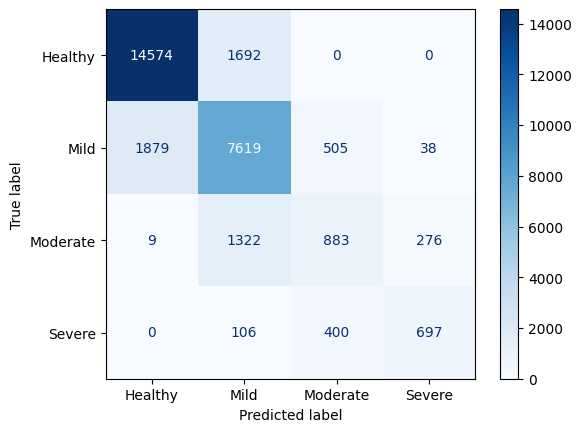

In [27]:
from sklearn.metrics import confusion_matrix, classification_report,accuracy_score,ConfusionMatrixDisplay
Score=accuracy_score(y_test,ypred)
cm=confusion_matrix(y_test,ypred)
cmd=ConfusionMatrixDisplay(cm,display_labels=model.classes_)
cmd.plot(cmap='Blues')
print(Score)
print(cm)
print(classification_report(y_test,ypred))

In [29]:
import pickle
pickle.dump(model,open('model.pkl','wb'))

In [31]:
x.dtypes

,0
age,int64
gender,int64
occupation,int64
bmi,float64
country,int64
sleep_duration_hrs,float64
sleep_quality_score,float64
rem_percentage,float64
deep_sleep_percentage,float64
sleep_latency_mins,int64


In [35]:
x.columns

Index(['age', 'gender', 'occupation', 'bmi', 'country', 'sleep_duration_hrs',
       'sleep_quality_score', 'rem_percentage', 'deep_sleep_percentage',
       'sleep_latency_mins', 'wake_episodes_per_night',
       'caffeine_mg_before_bed', 'alcohol_units_before_bed',
       'screen_time_before_bed_mins', 'exercise_day', 'steps_that_day',
       'nap_duration_mins', 'stress_score', 'work_hours_that_day',
       'chronotype', 'mental_health_condition', 'heart_rate_resting_bpm',
       'sleep_aid_used', 'shift_work', 'room_temperature_celsius',
       'weekend_sleep_diff_hrs', 'season', 'day_type',
       'cognitive_performance_score', 'felt_rested'],
      dtype='object')

In [37]:
for i in x.columns:
  print("min",i,":",x[i].min())
  print("max",i,":",x[i].max())

min age : 18
max age : 69
min gender : 0
max gender : 2
min occupation : 0
max occupation : 11
min bmi : 16.0
max bmi : 45.0
min country : 0
max country : 14
min sleep_duration_hrs : 3.0
max sleep_duration_hrs : 10.5
min sleep_quality_score : 1.0
max sleep_quality_score : 10.0
min rem_percentage : 10.0
max rem_percentage : 30.0
min deep_sleep_percentage : 5.0
max deep_sleep_percentage : 30.0
min sleep_latency_mins : 1
max sleep_latency_mins : 58
min wake_episodes_per_night : 0
max wake_episodes_per_night : 8
min caffeine_mg_before_bed : 0
max caffeine_mg_before_bed : 400
min alcohol_units_before_bed : 0.0
max alcohol_units_before_bed : 6.0
min screen_time_before_bed_mins : 2
max screen_time_before_bed_mins : 180
min exercise_day : 0
max exercise_day : 1
min steps_that_day : 500
max steps_that_day : 20000
min nap_duration_mins : 0
max nap_duration_mins : 116
min stress_score : 1.0
max stress_score : 10.0
min work_hours_that_day : 0.0
max work_hours_that_day : 18.0
min chronotype : 0
max